In [1]:
# Standard Libraries & Visualization
import warnings

from typing import Dict, List, Optional, Tuple
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Scikit-Learn Preprocessing & Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Scikit-Learn Model Selection & Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)

# Machine Learning Classifiers
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Plotting & Warning Configurations
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Global Reproducibility Seed
SEED = 42

In [2]:

def step_1_load_and_clean_data(file_path: str = "Travel_Insurance_Prediction.csv") -> pd.DataFrame:
    """Loads raw Travel Insurance dataset, standardizes column names, handles missing values,
    removes duplicate records, and formats data types.
    """
    print("=" * 60)
    print("STARTING STEP 1: LOAD & CLEAN DATA")
    print("=" * 60)
    
    try:
        df: pd.DataFrame = pd.read_csv(file_path, low_memory=False)
        print(f"[SUCCESS] Dataset loaded successfully from '{file_path}'.")
        print(f" -> Initial Rows: {df.shape[0]} | Initial Columns: {df.shape[1]}")
    except FileNotFoundError:
        print(f"[WARNING] File '{file_path}' not found. Generating synthetic demo dataset.")
        df = generate_demo_dataset()
        print(f"[SUCCESS] Synthetic dataset generated with shape: {df.shape[0]} rows, {df.shape[1]} columns.")

    # 1. Drop index column if present
    if 'Unnamed: 0' in df.columns:
        df.drop(columns=['Unnamed: 0'], inplace=True)

    # 2. Standardize Column Names
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

    # 3. Target Standardizing
    target_col: str = ("travelinsurance" if "travelinsurance" in df.columns else "target")
    if target_col in df.columns and target_col != "target":
        df.rename(columns={target_col: "target"}, inplace=True)
        print(" -> Standardized target label column to 'target'.")

    # 4. Handle Duplicates & Missing Values
    initial_count: int = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f" -> Removed {initial_count - len(df)} duplicate records.")

    print("=" * 60)
    print("STEP 1 COMPLETED SUCCESSFULLY")
    print(f" -> Final Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    print("=" * 60)
    return df

# Call the function and assign directly to tip_df
tip_df = step_1_load_and_clean_data("Travel_Insurance_Prediction.csv")
tip_df.head()

STARTING STEP 1: LOAD & CLEAN DATA
[SUCCESS] Dataset loaded successfully from 'Travel_Insurance_Prediction.csv'.
 -> Initial Rows: 1987 | Initial Columns: 10
 -> Standardized target label column to 'target'.
 -> Removed 738 duplicate records.
STEP 1 COMPLETED SUCCESSFULLY
 -> Final Dataset Shape: 1249 rows, 9 columns


,age,employment_type,graduateornot,annualincome,familymembers,chronicdiseases,frequentflyer,evertravelledabroad,target
0,31,Government Sector,Yes,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


In [4]:
import pandas as pd

def step_2_feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    """Creates the top 3 most important domain features for travel insurance prediction."""
    print("=" * 60)
    print("STARTING STEP 2: ADVANCED FEATURE ENGINEERING")
    print("=" * 60)
    
    df_fe = df.copy()

    # 1. Income Per Family Member (Per Capita Household Income)
    if "annualincome" in df_fe.columns and "familymembers" in df_fe.columns:
        df_fe["income_per_family_member"] = df_fe["annualincome"] / df_fe["familymembers"]
        print(" -> Created feature 1: 'income_per_family_member'")

    # 2. High-Risk Traveler Flag (Frequent Flyer + International Traveler)
    if "frequentflyer" in df_fe.columns and "evertravelledabroad" in df_fe.columns:
        df_fe["high_risk_traveler"] = (
            (df_fe["frequentflyer"].astype(str).str.lower() == "yes") & 
            (df_fe["evertravelledabroad"].astype(str).str.lower() == "yes")
        ).astype(int)
        print(" -> Created feature 2: 'high_risk_traveler'")

    # 3. High Income Flag (Affluent Customer Indicator)
    if "annualincome" in df_fe.columns:
        income_threshold = df_fe["annualincome"].median()
        df_fe["is_high_income"] = (df_fe["annualincome"] >= income_threshold).astype(int)
        print(" -> Created feature 3: 'is_high_income'")

    print("=" * 60)
    print("STEP 2 COMPLETED SUCCESSFULLY")
    print(f" -> Final Dataset Shape: {df_fe.shape[0]} rows, {df_fe.shape[1]} columns")
    print("=" * 60)
    return df_fe

# Display settings to show all 12 columns in notebook outputs
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Execute Step 2 and display the first 12 rows
tip_df_fe = step_2_feature_engineering(tip_df)
tip_df_fe.head(6)

STARTING STEP 2: ADVANCED FEATURE ENGINEERING
 -> Created feature 1: 'income_per_family_member'
 -> Created feature 2: 'high_risk_traveler'
 -> Created feature 3: 'is_high_income'
STEP 2 COMPLETED SUCCESSFULLY
 -> Final Dataset Shape: 1249 rows, 12 columns


,age,employment_type,graduateornot,annualincome,familymembers,chronicdiseases,frequentflyer,evertravelledabroad,target,income_per_family_member,high_risk_traveler,is_high_income
0,31,Government Sector,Yes,400000,6,1,No,No,0,66666.666667,0,0
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0,178571.428571,0,1
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1,125000.000000,0,0
3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0,233333.333333,0,0
4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0,87500.000000,0,0
5,25,Private Sector/Self Employed,No,1150000,4,0,No,No,0,287500.000000,0,1


STARTING STEP 3: EXPLORATORY DATA ANALYSIS (12 CHARTS TOTAL)
Generating 1 Chart for each of the 12 features...



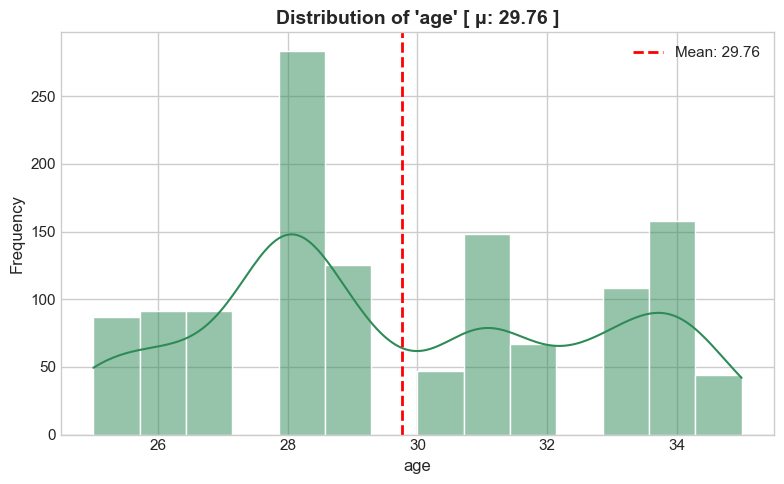

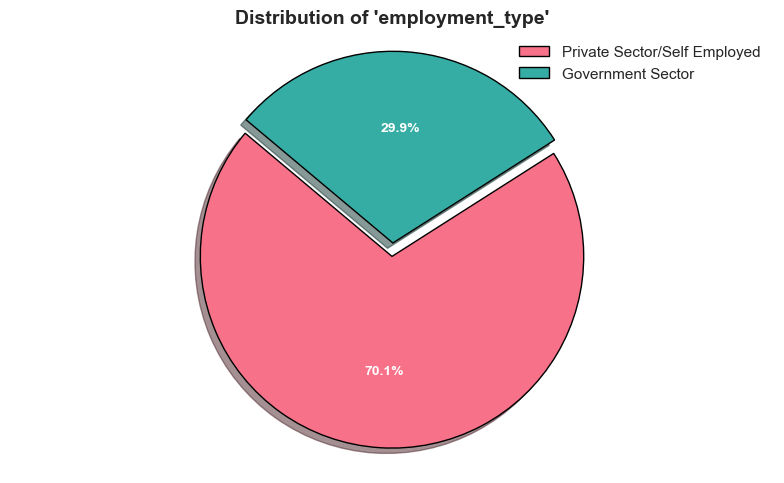

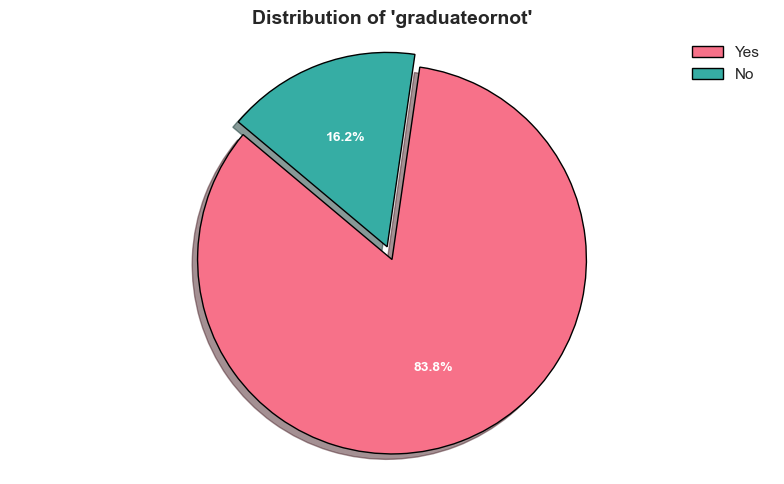

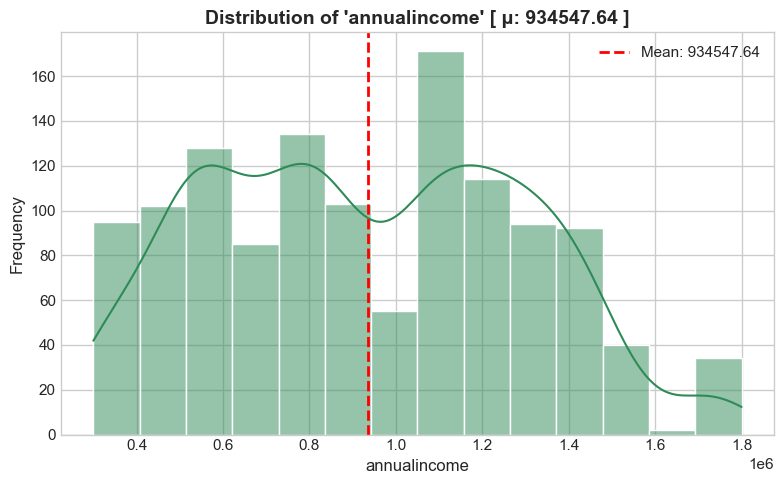

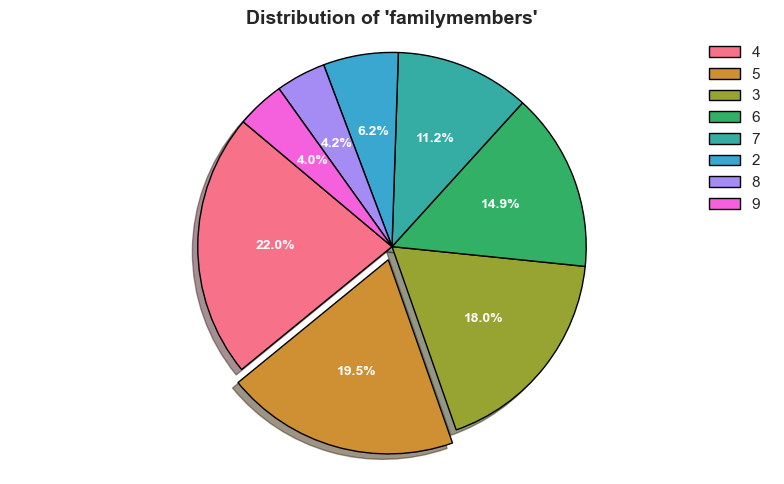

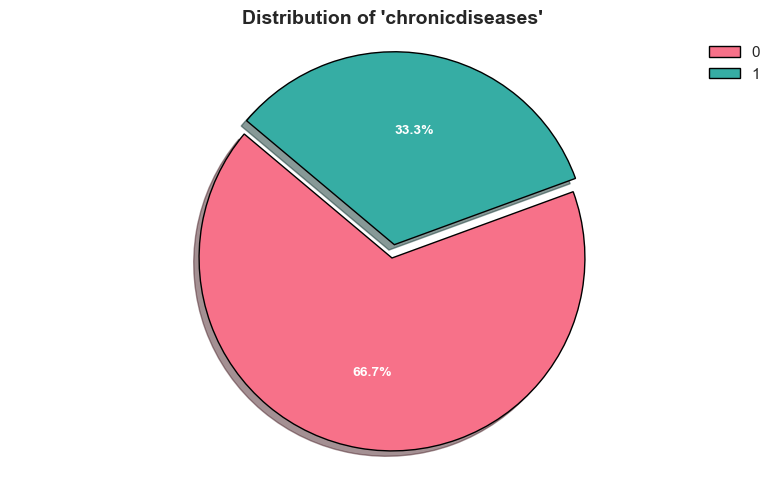

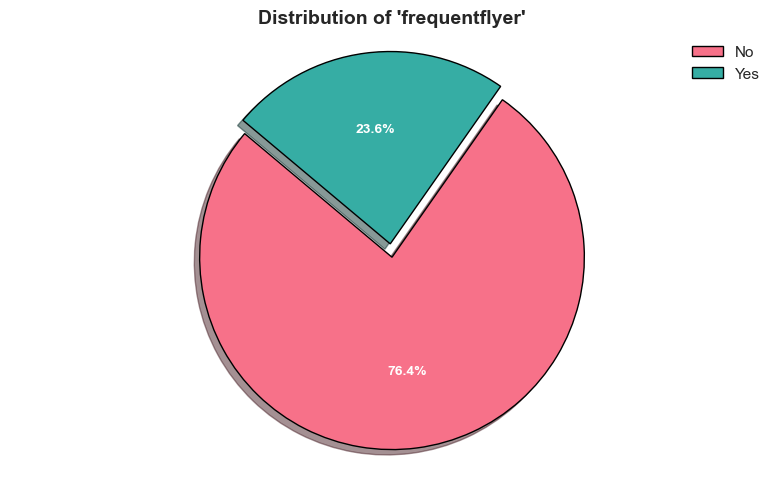

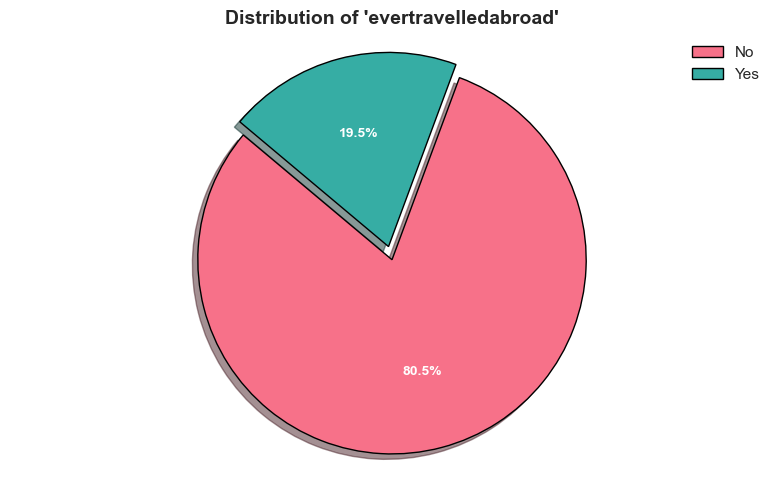

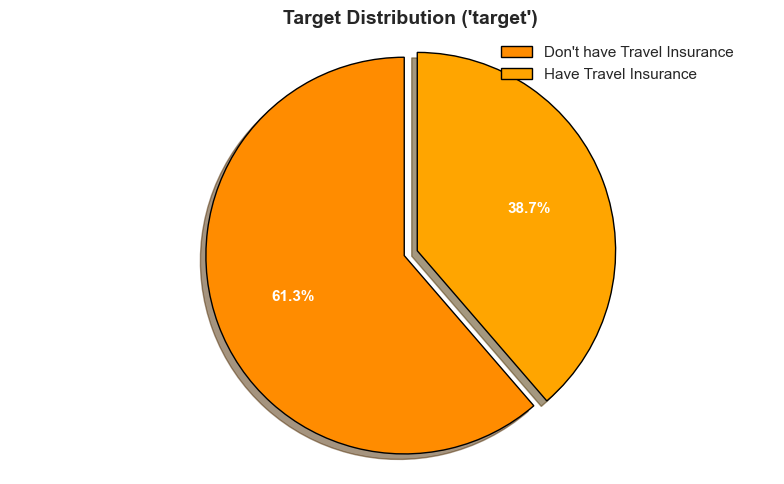

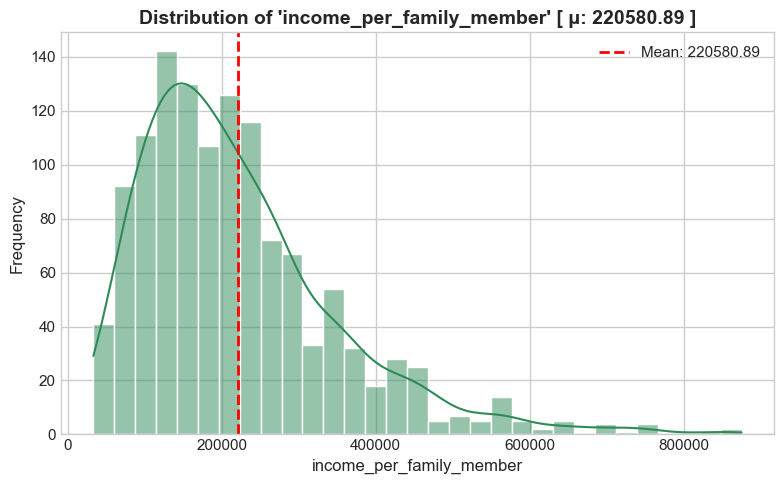

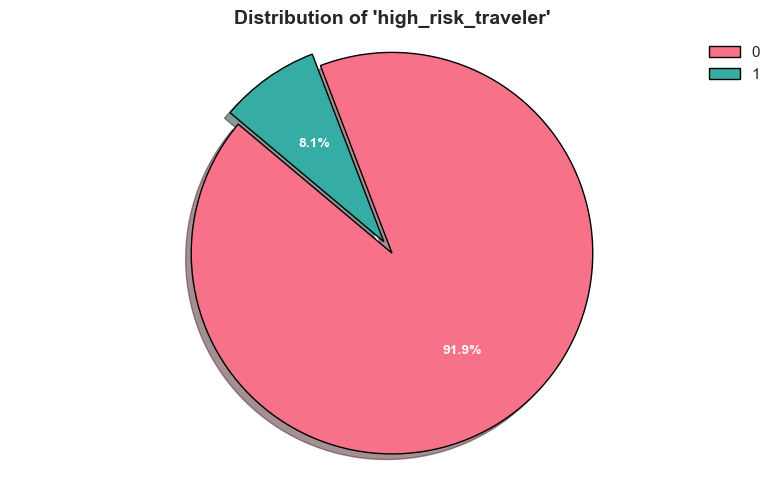

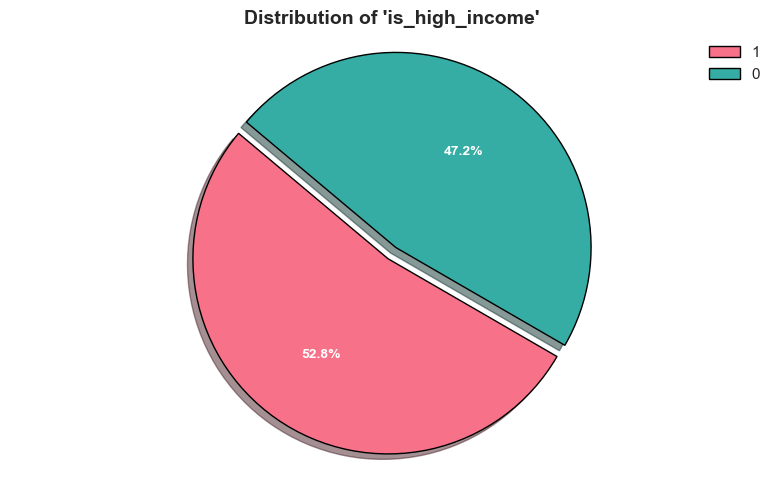

STEP 3 EDA COMPLETED SUCCESSFULLY (12 CHARTS GENERATED)


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def step_3_exploratory_data_analysis(
    df: pd.DataFrame, target_col: str = "target"
) -> None:
    """Executes Step 3 EDA: Uses Pie Charts for categorical/discrete features and Mean-Line Histograms for continuous features."""
    print("=" * 60)
    print("STARTING STEP 3: EXPLORATORY DATA ANALYSIS (12 CHARTS TOTAL)")
    print("=" * 60)

    # Set clean style
    plt.style.use("seaborn-v0_8-whitegrid")

    df_plot = df.copy()

    # Map target 0 -> "Don't have Travel Insurance" and 1 -> "Have Travel Insurance"
    target_label_map = {
        0: "Don't have Travel Insurance",
        1: "Have Travel Insurance",
    }
    if target_col in df_plot.columns and set(
        df_plot[target_col].unique()
    ).issubset({0, 1}):
        df_plot["target_label"] = df_plot[target_col].map(target_label_map)
        display_target = "target_label"
    else:
        display_target = target_col

    # Identify all 12 columns in exact dataset order
    all_columns = df_plot.columns.tolist()
    if "target_label" in all_columns:
        all_columns.remove("target_label")

    print(f"Generating 1 Chart for each of the {len(all_columns)} features...\n")

    for col in all_columns:
        fig, ax = plt.subplots(figsize=(8, 5))

        # ---------------------------------------------------------
        # Case 1: Target Feature Plot (Styled Pie Chart - Image 5)
        # ---------------------------------------------------------
        if col == target_col or col == display_target:
            target_counts = df_plot[display_target].value_counts()
            wedges, texts, autotexts = ax.pie(
                x=target_counts,
                labels=target_counts.index,
                colors=["darkorange", "orange"],
                autopct="%1.1f%%",
                explode=(0, 0.07),
                shadow=True,
                startangle=90,
                wedgeprops={"edgecolor": "black"},
                textprops=dict(color="white", fontsize=11),
            )
            ax.set_title(
                f"Target Distribution ('{col}')",
                fontsize=14,
                fontweight="bold",
            )
            ax.axis("equal")
            plt.setp(autotexts, weight="bold")
            plt.legend(target_counts.index, loc="upper right")

        # ---------------------------------------------------------
        # Case 2: Continuous Numerical Features (Mean Line Histogram - Image 2)
        # ---------------------------------------------------------
        elif (
            df_plot[col].dtype in ["int64", "float64"]
            and df_plot[col].nunique() > 10
        ):
            sns.histplot(df_plot[col], kde=True, color="seagreen", ax=ax)
            mean_val = df_plot[col].mean()
            ax.axvline(
                mean_val,
                color="red",
                linestyle="--",
                linewidth=2,
                label=f"Mean: {mean_val:.2f}",
            )
            ax.set_title(
                f"Distribution of '{col}' [ μ: {mean_val:.2f} ]",
                fontsize=14,
                fontweight="bold",
            )
            ax.set_xlabel(col, fontsize=12)
            ax.set_ylabel("Frequency", fontsize=12)
            ax.tick_params(axis="both", labelsize=11)
            ax.legend(loc="upper right")

        # ---------------------------------------------------------
        # Case 3: Categorical & Discrete Features (Exploded Pie Chart - Image 3 & 5)
        # ---------------------------------------------------------
        else:
            cat_counts = df_plot[col].value_counts()
            num_categories = len(cat_counts)

            # Create explode slice list for pie chart pop-out effect
            explode_vals = [0.07 if i == 1 else 0 for i in range(num_categories)]

            wedges, texts, autotexts = ax.pie(
                x=cat_counts,
                labels=cat_counts.index,
                colors=sns.color_palette("husl", num_categories),
                autopct="%1.1f%%",
                explode=explode_vals if num_categories > 1 else None,
                shadow=True,
                startangle=140,
                wedgeprops={"edgecolor": "black"},
                textprops=dict(color="white", fontsize=10),
            )
            ax.set_title(
                f"Distribution of '{col}'", fontsize=14, fontweight="bold"
            )
            ax.axis("equal")
            plt.setp(autotexts, weight="bold")
            plt.legend(cat_counts.index, loc="upper right")

        plt.tight_layout()
        plt.show()

    print("=" * 60)
    print("STEP 3 EDA COMPLETED SUCCESSFULLY (12 CHARTS GENERATED)")
    print("=" * 60)


# ==========================================
# EXECUTION CALL
# ==========================================
step_3_exploratory_data_analysis(df=tip_df_fe, target_col="target")

1. MACHINE LEARNING MODEL TRAINING
STEP 4 MODEL TRAINING & ANALYTICS COMPLETED SUCCESSFULLY

--- 2. MODEL PERFORMANCE EVALUATION SUMMARY ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.748,0.840000,0.432990,0.571429,0.686207
1,XGBoost (Tuned),0.748,0.854167,0.422680,0.565517,0.704636
2,AdaBoost,0.712,0.777778,0.360825,0.492958,0.665589
3,XGBoost Baseline,0.624,0.518072,0.443299,0.477778,0.649518
4,Extra Trees,0.604,0.488095,0.422680,0.453039,0.446938
5,Random Forest,0.616,0.506667,0.391753,0.441860,0.536251
6,Logistic Regression,0.660,0.611111,0.340206,0.437086,0.654168



--- 3. MODEL PERFORMANCE SUMMARY (RATES & PERCENTAGES) ---


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%)
0,Gradient Boosting,74.80%,84.00%,43.30%,57.14%,68.62%
1,XGBoost (Tuned),74.80%,85.42%,42.27%,56.55%,70.46%
2,AdaBoost,71.20%,77.78%,36.08%,49.30%,66.56%
3,XGBoost Baseline,62.40%,51.81%,44.33%,47.78%,64.95%
4,Extra Trees,60.40%,48.81%,42.27%,45.30%,44.69%
5,Random Forest,61.60%,50.67%,39.18%,44.19%,53.63%
6,Logistic Regression,66.00%,61.11%,34.02%,43.71%,65.42%



--- 4. PREDICTION INFERENCE (FINAL OUTCOME) ---


,Best Performing Model,Total Test Customers,Correctly Predicted,Incorrectly Predicted,True Positives (Purchased & Detected),True Negatives (No Purchase & Detected),"False Positives (Predicted Buy, Did Not)",False Negatives (Missed Buyers)
0,Gradient Boosting,250,187 (74.80%),63 (25.20%),42,145,8,55


STARTING STEP 5: VISUALIZATIONS & HEATMAPS


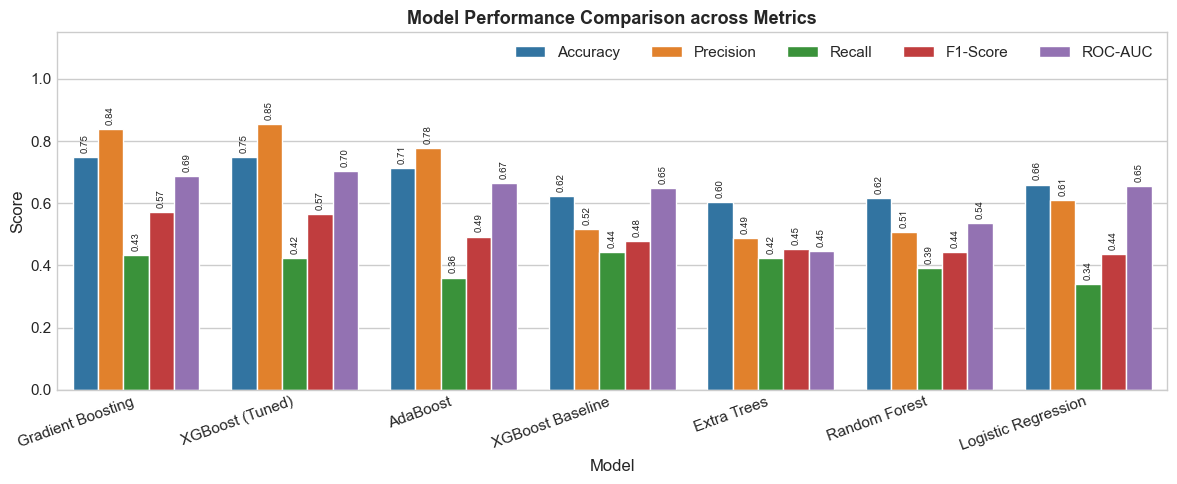

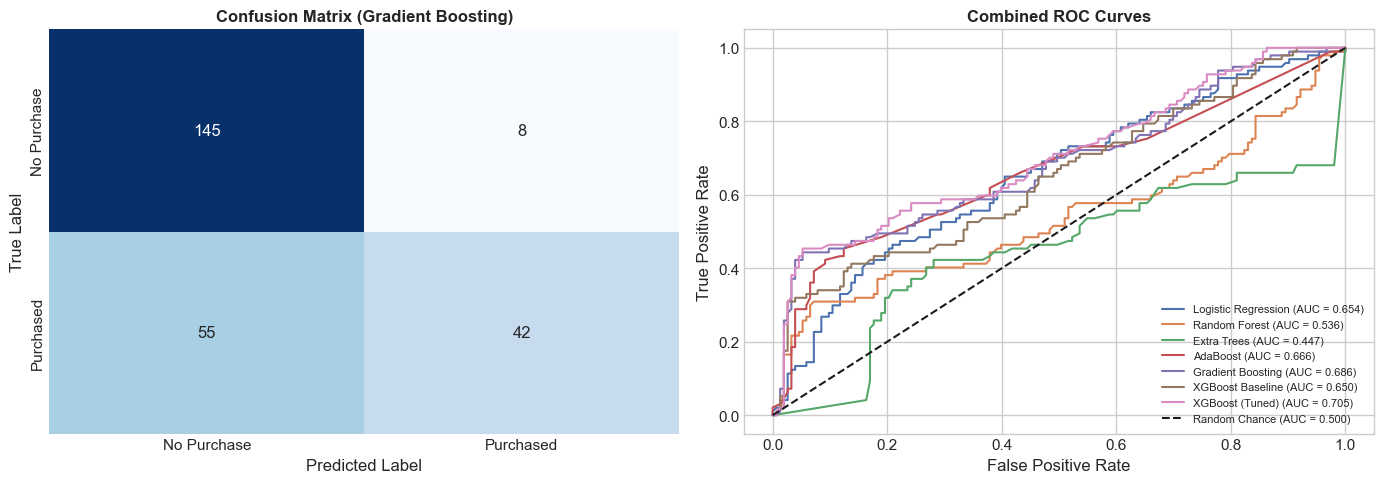

STEP 5 COMPLETED SUCCESSFULLY


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42

# ==============================================================================
# 1. DEFINE STEP 5: VISUALIZATIONS & HEATMAPS
# ==============================================================================
def step_5_visualizations_and_heatmaps(
    summary_df: pd.DataFrame,
    fitted_pipelines: dict,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    best_model_name: str = "Gradient Boosting",
) -> None:
    """Executes Step 5 visual analytics using model evaluation outputs."""
    print("=" * 70)
    print("STARTING STEP 5: VISUALIZATIONS & HEATMAPS")
    print("=" * 70)

    # A. Model Evaluation Metrics Comparison Chart
    metrics_melted = summary_df.melt(
        id_vars=["Model"],
        value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
        var_name="Metric",
        value_name="Score",
    )

    plt.figure(figsize=(12, 5))
    ax = sns.barplot(
        data=metrics_melted, x="Model", y="Score", hue="Metric", palette="tab10"
    )
    plt.title("Model Performance Comparison across Metrics", fontsize=13, fontweight="bold")
    plt.ylim(0, 1.15)
    plt.xticks(rotation=20, ha="right")

    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height > 0:
            ax.annotate(
                f"{height:.2f}",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center", va="bottom", fontsize=7, rotation=90,
                xytext=(0, 3), textcoords="offset points",
            )
    plt.legend(loc="upper right", ncol=5)
    plt.tight_layout()
    plt.show()

    # B. Confusion Matrix & ROC Curves
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    if best_model_name in fitted_pipelines:
        best_pipeline = fitted_pipelines[best_model_name]
        y_pred_best = best_pipeline.predict(X_test)
        cm = confusion_matrix(y_test, y_pred_best)

        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No Purchase", "Purchased"],
            yticklabels=["No Purchase", "Purchased"], ax=axes[0],
        )
        axes[0].set_title(f"Confusion Matrix ({best_model_name})", fontsize=12, fontweight="bold")
        axes[0].set_xlabel("Predicted Label")
        axes[0].set_ylabel("True Label")

    for model_name, pipeline in fitted_pipelines.items():
        if hasattr(pipeline, "predict_proba"):
            y_proba = pipeline.predict_proba(X_test)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_proba)
            auc_val = roc_auc_score(y_test, y_proba)
            axes[1].plot(fpr, tpr, label=f"{model_name} (AUC = {auc_val:.3f})")

    axes[1].plot([0, 1], [0, 1], "k--", label="Random Chance (AUC = 0.500)")
    axes[1].set_title("Combined ROC Curves", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

    print("=" * 70)
    print("STEP 5 COMPLETED SUCCESSFULLY")
    print("=" * 70)


# ==============================================================================
# 2. DATA PREPARATION & SPLIT
# ==============================================================================
X = tip_df_fe.drop(columns=["target"])
y = tip_df_fe["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)


# ==============================================================================
# 3. DEFINE STEP 4: MODEL TRAINING & COMPREHENSIVE OUTCOMES
# ==============================================================================
def step_4_advanced_model_training_and_analytics(
    X_train: pd.DataFrame,
    X_test: pd.DataFrame,
    y_train: pd.Series,
    y_test: pd.Series,
    preprocessor: ColumnTransformer,
) -> tuple:
    """Executes model training, evaluation summary, percentage rates, and prediction inference."""
    print("=" * 70)
    print("1. MACHINE LEARNING MODEL TRAINING")
    print("=" * 70)

    models = {
        "Logistic Regression": LogisticRegression(random_state=SEED),
        "Random Forest": RandomForestClassifier(random_state=SEED),
        "Extra Trees": ExtraTreesClassifier(random_state=SEED),
        "AdaBoost": AdaBoostClassifier(random_state=SEED),
        "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
        "XGBoost Baseline": XGBClassifier(random_state=SEED, eval_metric="logloss"),
        "XGBoost (Tuned)": XGBClassifier(
            n_estimators=100, learning_rate=0.05, max_depth=4, random_state=SEED, eval_metric="logloss"
        ),
    }

    fitted_pipelines = {}
    summary_list = []
    pct_summary_list = []

    for name, model in models.items():
        pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else None

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 0.0

        fitted_pipelines[name] = pipeline

        summary_list.append({
            "Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1, "ROC-AUC": roc_auc
        })
        pct_summary_list.append({
            "Model": name,
            "Accuracy (%)": f"{acc * 100:.2f}%",
            "Precision (%)": f"{prec * 100:.2f}%",
            "Recall (%)": f"{rec * 100:.2f}%",
            "F1-Score (%)": f"{f1 * 100:.2f}%",
            "ROC-AUC (%)": f"{roc_auc * 100:.2f}%",
        })

    summary_df = pd.DataFrame(summary_list).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
    pct_summary_df = pd.DataFrame(pct_summary_list).sort_values(by="F1-Score (%)", ascending=False).reset_index(drop=True)

    best_model_name = summary_df.iloc[0]["Model"]
    best_pipeline = fitted_pipelines[best_model_name]
    y_best_pred = best_pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_best_pred)
    tn, fp, fn, tp = cm.ravel()
    total_samples = len(y_test)
    correct_preds = tn + tp
    incorrect_preds = fp + fn

    inference_df = pd.DataFrame([{
        "Best Performing Model": best_model_name,
        "Total Test Customers": total_samples,
        "Correctly Predicted": f"{correct_preds} ({(correct_preds/total_samples)*100:.2f}%)",
        "Incorrectly Predicted": f"{incorrect_preds} ({(incorrect_preds/total_samples)*100:.2f}%)",
        "True Positives (Purchased & Detected)": tp,
        "True Negatives (No Purchase & Detected)": tn,
        "False Positives (Predicted Buy, Did Not)": fp,
        "False Negatives (Missed Buyers)": fn,
    }])

    print("=" * 70)
    print("STEP 4 MODEL TRAINING & ANALYTICS COMPLETED SUCCESSFULLY")
    print("=" * 70)

    return summary_df, pct_summary_df, inference_df, fitted_pipelines


# ==============================================================================
# 4. RUN PIPELINE & DISPLAY ALL OUTCOMES
# ==============================================================================

# Run Step 5
summary_df, pct_summary_df, inference_df, fitted_pipelines = step_4_advanced_model_training_and_analytics(
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor,
)

# Display Summaries
print("\n--- 2. MODEL PERFORMANCE EVALUATION SUMMARY ---")
display(summary_df)

print("\n--- 3. MODEL PERFORMANCE SUMMARY (RATES & PERCENTAGES) ---")
display(pct_summary_df)

print("\n--- 4. PREDICTION INFERENCE (FINAL OUTCOME) ---")
display(inference_df)

# Trigger Step 4 Visualizations
step_5_visualizations_and_heatmaps(
    summary_df=summary_df,
    fitted_pipelines=fitted_pipelines,
    X_test=X_test,
    y_test=y_test,
    best_model_name=summary_df.iloc[0]["Model"],
)